# Estimating a Graphon with JGS (Joint Graph Sorting)

This notebook clones and runs the **original** JGS code directly (no reimplementation) for one example graphon, then plots the true graphon against the estimated one.

**JGS (Joint Graph Sorting)** jointly aligns the nodes of several observed graphs -- possibly of different sizes, with no node correspondence across networks -- in order to estimate a common underlying graphon. It's designed to be both accurate and computationally efficient, scaling close to linearly with the total number of observed edges.

Reference: Sogan & Rebafka, *"Low-Complexity and Consistent Graphon Estimation from Multiple Networks"*, AISTATS 2026.
Code: [https://github.com/RolandBonifaceSogan/JGS-graphon](https://github.com/RolandBonifaceSogan/JGS-graphon)

## 1. Clone the repo and install dependencies

In [1]:
import shutil, os

repo_root = "JGS-graphon"
if os.path.exists(repo_root):
    shutil.rmtree(repo_root)  # remove any stale/incomplete previous clone

In [ ]:
import sys

!git clone -q https://github.com/RolandBonifaceSogan/JGS-graphon.git
!pip install -q numpy scipy matplotlib pandas POT scikit-image python-igraph

# graphons.py (your helper module): download on Colab, read from ../src locally
if "google.colab" in sys.modules:
    BASE = "https://raw.githubusercontent.com/sevvandi/sevvandi.github.io/BRANCH/assets/notebooks/NeurIPS_2026/src"
    !wget -q {BASE}/graphons.py
else:
    sys.path.insert(0, "../src")

Cloning into 'JGS-graphon'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 82 (delta 28), reused 70 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 2.54 MiB | 5.53 MiB/s, done.
Resolving deltas: 100% (28/28), done.
  Using cached imageio-2.37.2-py3-none-any.whl.metadata (9.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 6.1 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 6.3 MB/s  0:00:02 eta 0:00:01
Using cached imageio-2.37.2-py3-none-any.whl (317 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pandas]2m6/7 [pandas]image]


## 2. Point Python at the cloned repo and import their code

In [1]:
import sys, os

repo_dir = os.path.join(os.getcwd(), "JGS-graphon")

# sanity check before importing anything
expected_files = [os.path.join("src", "jgs_estimator.py"), os.path.join("src", "jgs_utils.py")]
missing = [f for f in expected_files if not os.path.exists(os.path.join(repo_dir, f))]
if missing:
    raise FileNotFoundError(f"Missing from {repo_dir}: {missing} -- clone may be incomplete")

sys.path.insert(0, repo_dir)

import numpy as np
import matplotlib.pyplot as plt

from src.jgs_utils import *      # generate_graphs_from_graphon, generate_true_graphon_matrix,
                                  # graphon_L2_norm, gw_distance, resize_graphon_to_common
from src.jgs_estimator import *  # joint_graph_sorting_estimate, interpolate_graphon

## 3. Simulation setup: pick a graphon and generate observed graphs

In [4]:
vec_n = [100, 150, 200]   # sizes of the observed graphs (different sizes, no node correspondence)
graphon_id = 5            # choose from 0 to 11 (the repo's built-in synthetic graphons)
graphon_size = 1000       # resolution to evaluate the true/estimated graphon at

data = generate_graphs_from_graphon(vec_n, graphon_id)
graphs = data["graphs"]

W_true = generate_true_graphon_matrix(graphon_size, graphon_id)

print(f"Graphon id {graphon_id}: generated {len(graphs)} graphs of sizes {vec_n}")

Graphon id 5: generated 3 graphs of sizes [100, 150, 200]


## 4. Estimate the graphon with JGS (with and without smoothing)

In [8]:
est1 = joint_graph_sorting_estimate(graphs, smoothing=False, target_size=graphon_size)
est2 = joint_graph_sorting_estimate(graphs, smoothing=True, target_size=graphon_size)

mse1 = graphon_L2_norm(est1["graphon_resized"], W_true)
mse2 = graphon_L2_norm(est2["graphon_resized"], W_true)
print(f"L2 error (no smoothing):   {mse1:.4f}")
print(f"L2 error (with smoothing): {mse2:.4f}")

L2 error (no smoothing):   0.0008
L2 error (with smoothing): 0.0004


### Optional: estimate with a specific number of blocks

`k` controls the number of blocks JGS partitions the nodes into before smoothing; if omitted, the estimator selects it automatically (as used above).

In [9]:
est3 = joint_graph_sorting_estimate(graphs, k=50, smoothing=True, target_size=graphon_size)
mse3 = graphon_L2_norm(est3["graphon_resized"], W_true)
print(f"L2 error with k=50: {mse3:.4f}")

L2 error with k=50: 0.0028


## 5. Plot the true graphon against the estimated graphon

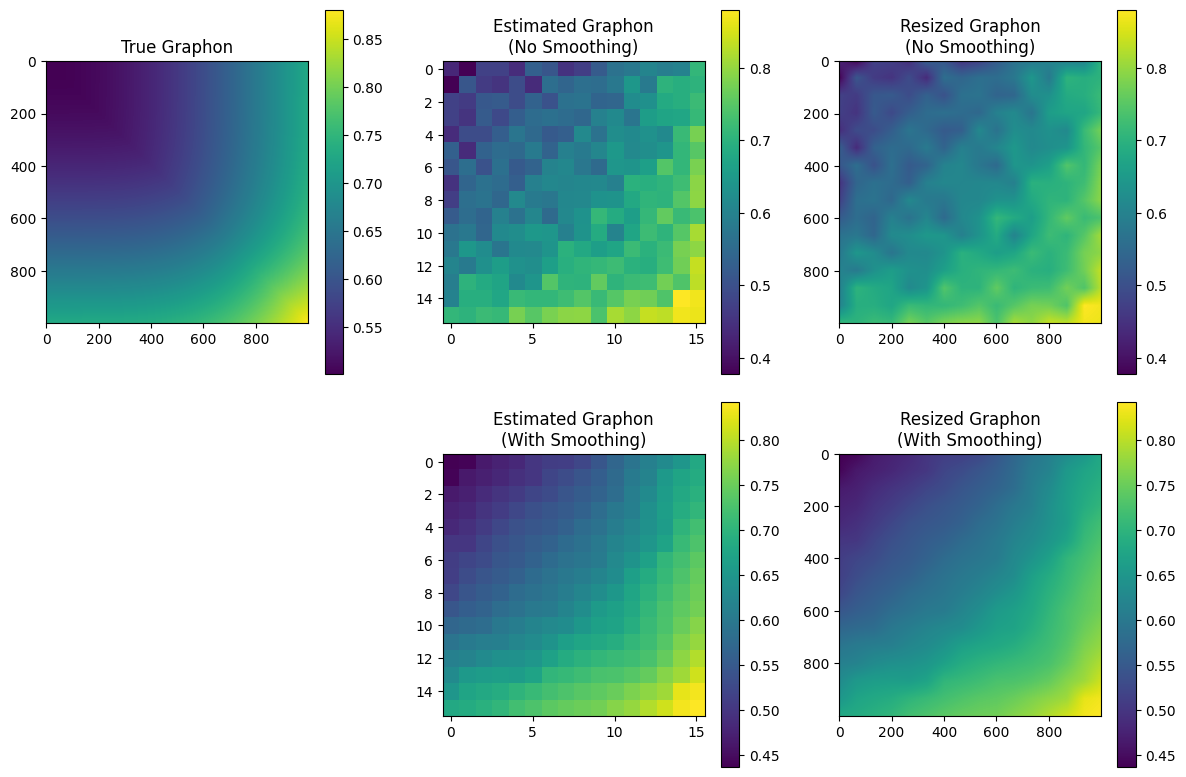

In [10]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(W_true, cmap='viridis')
plt.title('True Graphon')
plt.colorbar()

plt.subplot(2, 3, 2)
plt.imshow(est1["edge_frequencies"], cmap='viridis')
plt.title('Estimated Graphon\n(No Smoothing)')
plt.colorbar()

plt.subplot(2, 3, 3)
plt.imshow(est1["graphon_resized"], cmap='viridis')
plt.title('Resized Graphon\n(No Smoothing)')
plt.colorbar()

plt.subplot(2, 3, 5)
plt.imshow(est2["edge_frequencies"], cmap='viridis')
plt.title('Estimated Graphon\n(With Smoothing)')
plt.colorbar()

plt.subplot(2, 3, 6)
plt.imshow(est2["graphon_resized"], cmap='viridis')
plt.title('Resized Graphon\n(With Smoothing)')
plt.colorbar()

plt.tight_layout()
plt.show()

## Evaluating the estimated graphon $\hat{W}$

/var/folders/ll/9zkrydn1623cpl0964r_lnp00000gp/T/ipykernel_18765/53321437.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([true_vals, est_vals], labels=["True graphon", "Estimated graphon"], showfliers=False)
/var/folders/ll/9zkrydn1623cpl0964r_lnp00000gp/T/ipykernel_18765/53321437.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([true_vals, est_vals], labels=["True graphon", "Estimated graphon"], showfliers=False)


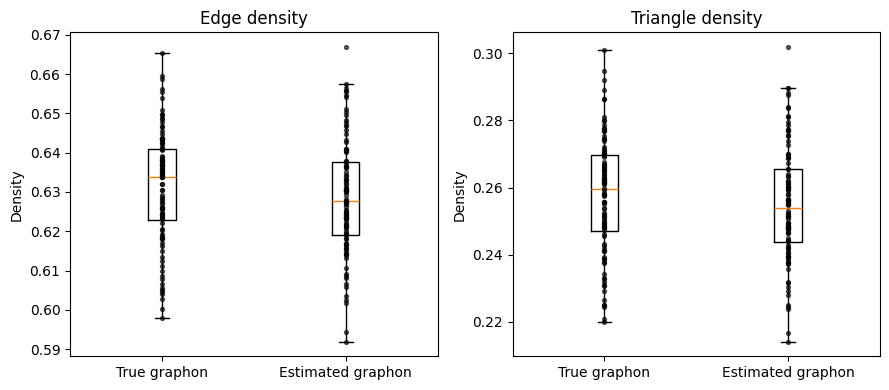

In [ ]:
from graphons import sample_graph_from_graphon, edge_density, triangle_density

n_graphs = 100
n_nodes = 100  # size of each sampled graph

edge_dens_true, edge_dens_est = [], []
tri_dens_true, tri_dens_est = [], []

for _ in range(n_graphs):
    A_true = sample_graph_from_graphon(W_true, n_nodes)
    A_est = sample_graph_from_graphon(est2["graphon_resized"], n_nodes)

    edge_dens_true.append(edge_density(A_true))
    edge_dens_est.append(edge_density(A_est))
    tri_dens_true.append(triangle_density(A_true))
    tri_dens_est.append(triangle_density(A_est))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (true_vals, est_vals), title in zip(
    axes,
    [(edge_dens_true, edge_dens_est), (tri_dens_true, tri_dens_est)],
    ["Edge density", "Triangle density"],
):
    ax.boxplot([true_vals, est_vals], labels=["True graphon", "Estimated graphon"], showfliers=False)
    ax.scatter(np.full(len(true_vals), 1), true_vals, color="black", alpha=0.6, s=8, zorder=3)
    ax.scatter(np.full(len(est_vals), 2), est_vals, color="black", alpha=0.6, s=8, zorder=3)
    ax.set_title(title)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()



We see that the estimated graphon produces graphs with matching edge and triangle density. 

## Notes

- `graphon_id` ranges from 0 to 11 -- try other values to see JGS's fit on different graphon shapes (smooth, block-structured, etc.).
- `edge_frequencies` is JGS's raw block-level estimate (one value per block, before resizing to `target_size`); `graphon_resized` is that estimate interpolated onto a common `graphon_size x graphon_size` grid for direct comparison with `W_true`.
- For benchmarking JGS against other methods (G-Mixup, SGWB, SIGL, etc.), see the repo's `experiments/comparisons.ipynb` -- that requires separately cloning/installing each of those methods' own repos, per the JGS README's reproducibility notes.